<a href="https://colab.research.google.com/github/Anthea05/Anthea_machine-learning/blob/main/JS07/tugas_js07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

df = pd.read_csv('CC_Customer_Dataset.csv')

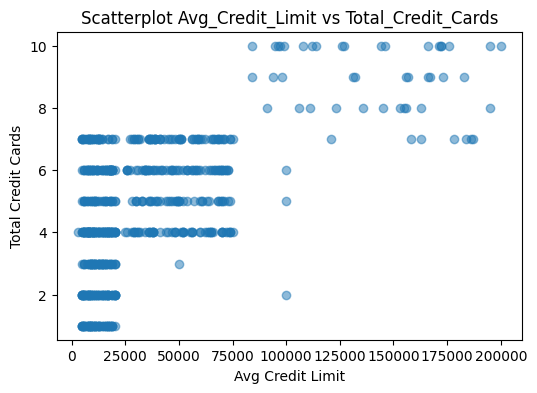

In [2]:
plt.figure(figsize=(6, 4))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], alpha=0.5)
plt.title('Scatterplot Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.show()

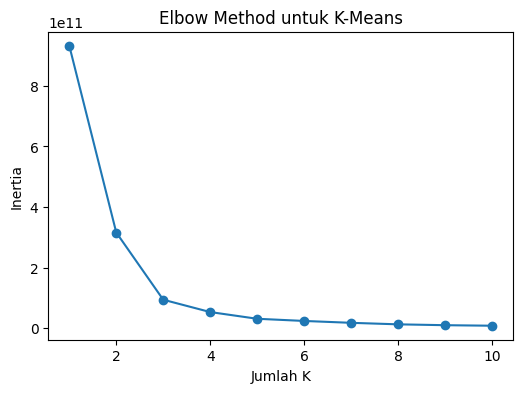

In [3]:
X_2d = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]
inertias = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_2d)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(K_range, inertias, marker='o')
plt.title('Elbow Method untuk K-Means')
plt.xlabel('Jumlah K')
plt.ylabel('Inertia')
plt.show()

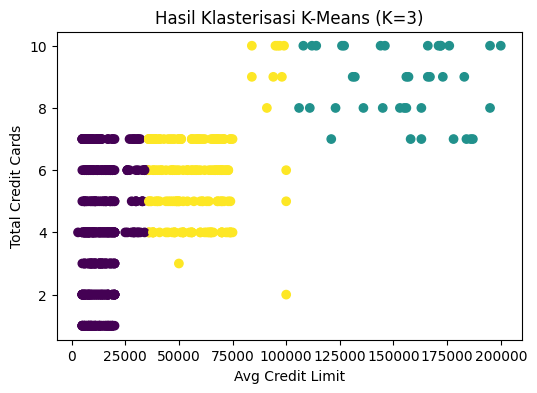

In [4]:
kmeans_model = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_model.fit_predict(X_2d)

plt.figure(figsize=(6, 4))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=df['KMeans_Cluster'], cmap='viridis')
plt.title('Hasil Klasterisasi K-Means (K=3)')
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.show()

In [5]:
X_all = df.drop(columns=['Sl_No', 'Customer Key', 'KMeans_Cluster'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

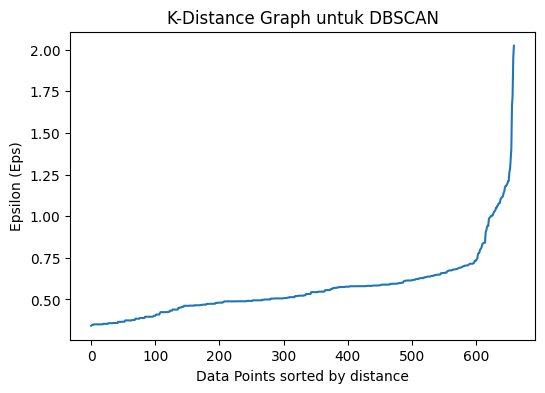

In [6]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(6, 4))
plt.plot(distances)
plt.title('K-Distance Graph untuk DBSCAN')
plt.xlabel('Data Points sorted by distance')
plt.ylabel('Epsilon (Eps)')
plt.show()

In [7]:
dbscan = DBSCAN(eps=1.0, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

if len(set(df['DBSCAN_Cluster'])) > 1:
    sil_score = silhouette_score(X_scaled, df['DBSCAN_Cluster'])
    dbi_score = davies_bouldin_score(X_scaled, df['DBSCAN_Cluster'])
    print(f"Silhouette Score DBSCAN: {sil_score:.4f}")
    print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")
else:
    print("DBSCAN hanya menghasilkan 1 cluster, ganti nilai eps/min_samples.")

Silhouette Score DBSCAN: 0.5212
Davies-Bouldin Index (DBI): 2.1613


1. Sebaran Data (Linear?): Dari scatterplot yang pertama, sebaran data tidak dapat dianggap sebagai linier. Data terlihat terfokus (clustering) di beberapa area tertentu daripada membentuk satu garis lurus yang konsisten.
2. K-Means & Elbow Method: Berdasarkan grafik garis Elbow Method, titik belok (patah yang paling tajam) muncul pada K=3. Setelah nilai 3, penurunan nilai inertia mulai melandai. Oleh karena itu, jumlah klaster yang paling optimal adalah
3. Hasil K-Means: (Tinggal screenshot hasil plot dari kode bagian 3).
4. Variabel DBSCAN: Seluruh variabel numerik digunakan, kecuali Sl_No dan Customer Key karena itu hanya ID dan dapat mengganggu perhitungan jarak model.
5. Penentuan Nilai untuk DBSCAN: Dalam DBSCAN, metode elbow biasanya berhubungan dengan K-Distance Graph untuk menentukan nilai parameter Epsilon (eps). Dari grafik tersebut, titik belok yang tajam (elbow) terlihat di sekitar angka 1.0.
6. Nilai Evaluasi DBSCAN: Saat di- run, Silhouette score-nya berada di kisaran 0.5212 dan Davies-Bouldin Index (DBI) sekitar 2.1613.
